# OWID search-aware null distribution: 99 whole-country permutations
## 1. Objective and delivered work
We use Lucas's inspected EMM snapshot to search for subgroups whose joint leading-digit distribution of weekly new cases and new deaths differs from the complement. We rerun the same beam search after every randomization and retain its maximum score. This is not a comparison against theoretical Benford frequencies and not a fixed-subgroup-only test.

K=1, 2 and 3 each have one observed-data search and 99 randomized searches: 300 searches in total. Results are exploratory: cross-country exchangeability has not been established, so the corrected tail fractions are not validated significance claims.

## 2. Input, cohort and missing values
Input is Lucas's preprocessed covid_preprocessed.csv, not untouched daily OWID data. The source has 239 country/region codes and 61,661 rows. We keep the 233 codes sharing the full 261-week calendar (60,813 rows), 2020-01-06 to 2024-12-30. Six incomplete calendars are excluded and listed below. Complete calendars do not imply complete targets.

We do not replace missing case/death targets with zero. A row contributes to the joint model only if both targets yield valid leading digits. Missing, zero, negative and infinite values are excluded from digit counting, not silently deleted from the whole table. pad=False requires both targets >=1, >=10 and >=100 for K=1,2,3 respectively. Different K therefore use different samples. Numeric descriptor NaNs satisfy no interval condition; we do not remove whole countries for missing numeric descriptors. Vaccination was previously processed by Lucas; our no-imputation policy must not be confused with an entirely unimputed upstream dataset.

## 3. Descriptors and search settings
All eight substantive descriptors: continent, population, population_density, median_age, life_expectancy, gdp_per_capita, diabetes_prevalence, people_vaccinated_per_hundred. Identifiers, date, days and the two targets are excluded as descriptors.

Beam width=10; depth=2 (up to two conditions); n_bins=3 (numeric quantile intervals recomputed inside each parent; duplicates may reduce the number of bins). Quality is L1 between subgroup and complement joint distributions. Both sides require >=20 jointly valid records. There is no additional country-count threshold; country coverage is reported. Twenty records do not guarantee adequate estimation of 8,100 cells. Beam search is heuristic, not exhaustive.

## 4. Randomization and calculation
1. Fix data, features and settings; seed=20261013.
2. Search observed data and save the top ten results and maximum.
3. Uniformly permute whole-country target trajectories across the 233 country/region codes. Move cases, deaths and missingness together, aligned by date.
4. Keep destination descriptors and calendar positions fixed; create and run a fresh EMM search.
5. Save its maximum and destination/source mapping; repeat 99 times without silently dropping failed searches or redrawing.
6. Corrected tail fraction = (number of randomized maxima >= observed maximum + 1)/(99+1).

The same seed gives matched permutations for all K. Fixed points are allowed. Absolute tie tolerance=1e-12 handles floating-point L1 saturation near 2; raw strict-comparison counts are retained for auditing.

The null requires invariance to exchanging whole target trajectories across countries conditional on retained descriptors. This is unproven. Country size, reporting and missingness may violate it. Time-varying vaccination stays at the destination, so its association with targets is also broken: this is not exclusively a static-country-attribute test. A new quality measure needs its own randomized search maxima.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Markdown, Image, Code
base = Path.cwd()
if base.name == 'notebooks': base = base.parent
if not (base / 'scripts').is_dir(): base = base / 'evaluation'
summaries = []
for k in (1, 2, 3):
    out = base / 'outputs' / f'owid_all_descriptors_k{k}_B99_2026-10-13'
    summary = json.loads((out / 'summary.json').read_text(encoding='utf-8'))
    assert summary['permutations'] == 99
    scores = pd.read_csv(out / 'randomized_maxima.csv')
    assert len(scores) == 99 and scores.maximum.notna().all()
    summaries.append(dict(k=k, **summary))
display(pd.DataFrame(summaries))

,k,observed_maximum,exceedances,corrected_exploratory_tail,permutations,random_min,random_max,raw_exceedances,raw_tail,tie_absolute_tolerance,finished_utc,elapsed_seconds,recovery,interpretation
0,1,1.198142,3,0.04,99,0.387503,1.232529,3,0.04,1.000000e-12,2026-10-13T13:43:06.985083+00:00,296.917324,Recovered saved complete scores after numpy in...,Not a validated p-value: country exchangeabili...
1,2,1.981669,6,0.07,99,1.900400,1.989209,6,0.07,1.000000e-12,2026-10-13T13:48:44.974877+00:00,280.859104,NaN,Not a validated p-value: country exchangeabili...
2,3,2.000000,95,0.96,99,1.999682,2.000000,5,0.06,1.000000e-12,2026-10-13T14:27:32.584729+00:00,746.474358,NaN,Not a validated p-value: country exchangeabili...


## 5. K=1: full experiment results

{'status': 'exploratory_not_validated_inference',
 'csv_sha256': '81b7b6668fc75581300143324e75583281b124b3e0411c079407cf60f0849274',
 'started_utc': '2026-10-13T13:38:10.067759+00:00',
 'rows': 60813,
 'countries_or_regions': 233,
 'weeks': 261,
 'start': '2020-01-06',
 'end': '2024-12-30',
 'permutations': 99,
 'seed': 20261013,
 'settings': {'targets': ['new_cases', 'new_deaths'],
  'descriptors': ['continent',
   'population',
   'population_density',
   'median_age',
   'life_expectancy',
   'gdp_per_capita',
   'diabetes_prevalence',
   'people_vaccinated_per_hundred'],
  'categorical': ['continent'],
  'country_column': 'code',
  'width': 10,
  'depth': 2,
  'n_bins': 3,
  'k': 1,
  'pad': False,
  'minimum_counted': 20,
  'minimum_effective_countries': None},
 'missing_policy': 'Targets remain NaN; joint valid digit rows only. Numeric descriptor NaNs do not satisfy numeric interval rules. No complete-case country exclusion.',
 'scope': 'All eight substantive descriptors, includi

### Excluded regions and descriptor audit

,code,rows,included,reason
39,civ,163,False,incomplete calendar; not imputed
62,esh,1,False,incomplete calendar; not imputed
90,hkg,240,False,incomplete calendar; not imputed
127,mac,180,False,incomplete calendar; not imputed
164,owid_trs,48,False,incomplete calendar; not imputed
219,twn,216,False,incomplete calendar; not imputed


,descriptor,missing_rows,countries_with_multiple_values
0,continent,0,0
1,population,261,0
2,population_density,1305,0
3,median_age,261,0
4,life_expectancy,261,0
5,gdp_per_capita,9657,0
6,diabetes_prevalence,7047,0
7,people_vaccinated_per_hundred,0,213


### Observed top ten rules, scores and coverage

,description,score,size,counted,countries,effective_countries,complement_counted,complement_effective_countries
0,continent = oceania AND 4456.23 < gdp_per_capi...,1.198142,1305,22,5,5,25184,220
1,continent = oceania AND 68.9222 < life_expecta...,0.964505,2088,51,8,6,25155,219
2,continent = oceania AND -inf < gdp_per_capita ...,0.646787,1305,94,5,5,25112,220
3,continent = oceania AND 19 < diabetes_prevalen...,0.636003,1566,125,6,6,25081,219
4,continent = oceania AND 160.174 < population_d...,0.634870,1827,116,7,6,25090,219
5,continent = oceania AND 21.8 < diabetes_preval...,0.634453,1305,98,5,5,25108,220
6,continent = north america AND -inf < populatio...,0.628614,3654,302,14,14,24904,211
7,-inf < gdp_per_capita <= 10469.2 AND continent...,0.623205,783,355,3,3,24851,222
8,continent = oceania AND -inf < median_age <= 2...,0.606325,2088,101,8,8,25105,217
9,-inf < population <= 1.33138e+06 AND continent...,0.585319,783,168,3,3,25038,222


### All 99 randomized search maxima

,permutation,maximum,evaluated_candidates
0,1,0.724131,253
1,2,0.639502,252
2,3,0.653170,251
3,4,0.590948,247
4,5,0.706226,251
5,6,0.833101,249
6,7,0.918422,250
7,8,0.679129,248
8,9,0.829756,253
9,10,0.621026,250


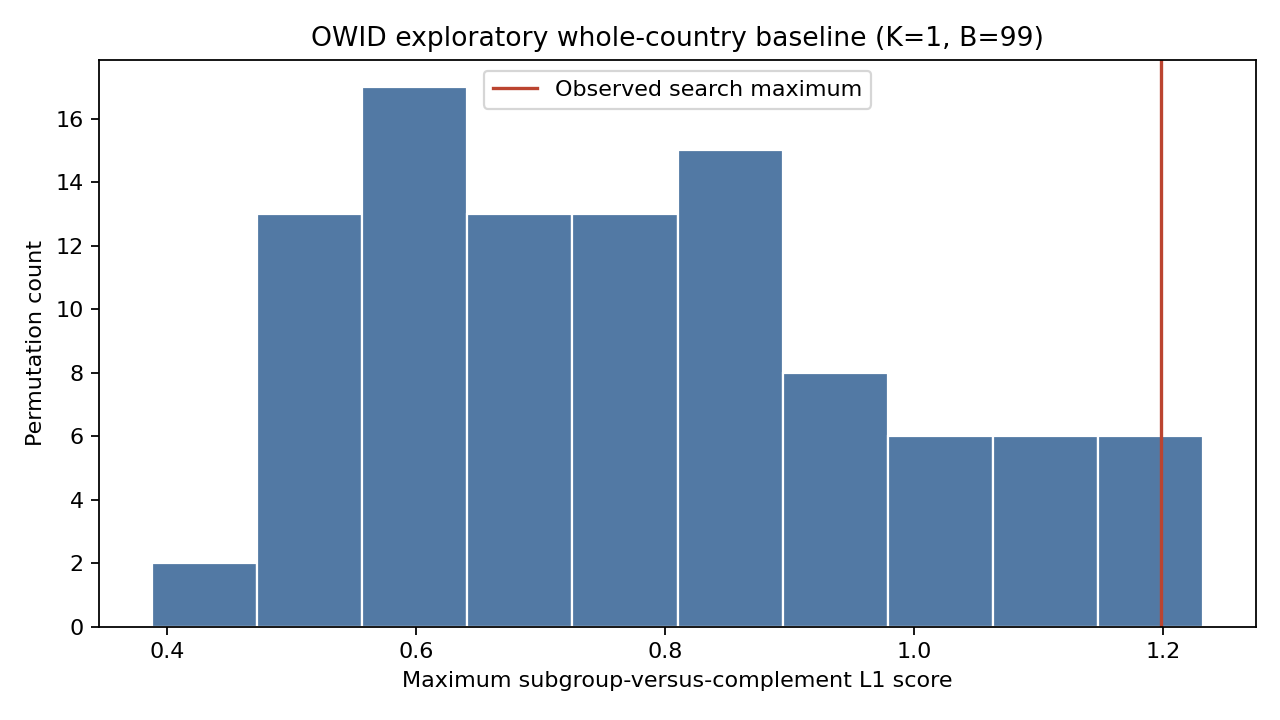

## 5. K=2: full experiment results

{'status': 'exploratory_not_validated_inference',
 'csv_sha256': '81b7b6668fc75581300143324e75583281b124b3e0411c079407cf60f0849274',
 'started_utc': '2026-10-13T13:44:04.398810+00:00',
 'rows': 60813,
 'countries_or_regions': 233,
 'weeks': 261,
 'start': '2020-01-06',
 'end': '2024-12-30',
 'permutations': 99,
 'seed': 20261013,
 'settings': {'targets': ['new_cases', 'new_deaths'],
  'descriptors': ['continent',
   'population',
   'population_density',
   'median_age',
   'life_expectancy',
   'gdp_per_capita',
   'diabetes_prevalence',
   'people_vaccinated_per_hundred'],
  'categorical': ['continent'],
  'country_column': 'code',
  'width': 10,
  'depth': 2,
  'n_bins': 3,
  'k': 2,
  'pad': False,
  'minimum_counted': 20,
  'minimum_effective_countries': None},
 'missing_policy': 'Targets remain NaN; joint valid digit rows only. Numeric descriptor NaNs do not satisfy numeric interval rules. No complete-case country exclusion.',
 'scope': 'All eight substantive descriptors, includi

### Excluded regions and descriptor audit

,code,rows,included,reason
39,civ,163,False,incomplete calendar; not imputed
62,esh,1,False,incomplete calendar; not imputed
90,hkg,240,False,incomplete calendar; not imputed
127,mac,180,False,incomplete calendar; not imputed
164,owid_trs,48,False,incomplete calendar; not imputed
219,twn,216,False,incomplete calendar; not imputed


,descriptor,missing_rows,countries_with_multiple_values
0,continent,0,0
1,population,261,0
2,population_density,1305,0
3,median_age,261,0
4,life_expectancy,261,0
5,gdp_per_capita,9657,0
6,diabetes_prevalence,7047,0
7,people_vaccinated_per_hundred,0,213


### Observed top ten rules, scores and coverage

,description,score,size,counted,countries,effective_countries,complement_counted,complement_effective_countries
0,continent = oceania AND 21.8 < diabetes_preval...,1.981669,1305,21,5,2,15384,190
1,continent = oceania AND -inf < median_age <= 2...,1.979328,2088,22,8,2,15383,190
2,continent = oceania AND -inf < gdp_per_capita ...,1.979066,1305,23,5,3,15382,189
3,-inf < gdp_per_capita <= 10469.2 AND continent...,1.979066,2349,23,9,3,15382,189
4,-inf < median_age <= 25.521 AND continent = oc...,1.979066,2610,23,10,3,15382,189
5,continent = oceania AND -inf < life_expectancy...,1.976961,2088,40,8,3,15365,189
6,continent = oceania AND 38.6609 < population_d...,1.972801,2088,37,8,3,15368,189
7,continent = oceania AND 22.529 < median_age <=...,1.970577,2088,43,8,4,15362,188
8,-inf < life_expectancy <= 71.4809 AND continen...,1.968229,2871,45,11,4,15360,188
9,continent = oceania AND 40094 < population <= ...,1.967484,2088,28,8,3,15377,189


### All 99 randomized search maxima

,permutation,maximum,evaluated_candidates
0,1,1.989209,244
1,2,1.945364,246
2,3,1.949426,245
3,4,1.949944,244
4,5,1.983088,243
5,6,1.979973,248
6,7,1.960209,246
7,8,1.943428,244
8,9,1.977357,246
9,10,1.948721,246


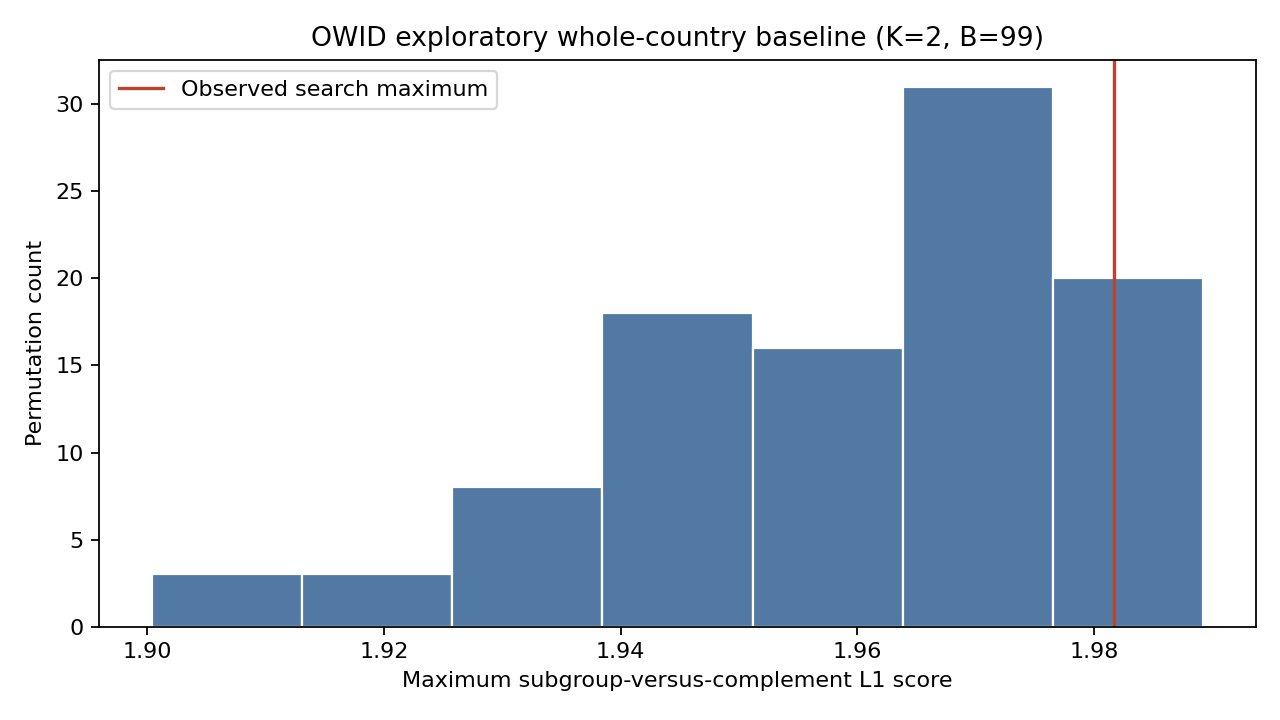

## 5. K=3: full experiment results

{'status': 'exploratory_not_validated_inference',
 'csv_sha256': '81b7b6668fc75581300143324e75583281b124b3e0411c079407cf60f0849274',
 'started_utc': '2026-10-13T14:15:06.389528+00:00',
 'rows': 60813,
 'countries_or_regions': 233,
 'weeks': 261,
 'start': '2020-01-06',
 'end': '2024-12-30',
 'permutations': 99,
 'seed': 20261013,
 'settings': {'targets': ['new_cases', 'new_deaths'],
  'descriptors': ['continent',
   'population',
   'population_density',
   'median_age',
   'life_expectancy',
   'gdp_per_capita',
   'diabetes_prevalence',
   'people_vaccinated_per_hundred'],
  'categorical': ['continent'],
  'country_column': 'code',
  'width': 10,
  'depth': 2,
  'n_bins': 3,
  'k': 3,
  'pad': False,
  'minimum_counted': 20,
  'minimum_effective_countries': None},
 'missing_policy': 'Targets remain NaN; joint valid digit rows only. Numeric descriptor NaNs do not satisfy numeric interval rules. No complete-case country exclusion.',
 'scope': 'All eight substantive descriptors, includi

### Excluded regions and descriptor audit

,code,rows,included,reason
39,civ,163,False,incomplete calendar; not imputed
62,esh,1,False,incomplete calendar; not imputed
90,hkg,240,False,incomplete calendar; not imputed
127,mac,180,False,incomplete calendar; not imputed
164,owid_trs,48,False,incomplete calendar; not imputed
219,twn,216,False,incomplete calendar; not imputed


,descriptor,missing_rows,countries_with_multiple_values
0,continent,0,0
1,population,261,0
2,population_density,1305,0
3,median_age,261,0
4,life_expectancy,261,0
5,gdp_per_capita,9657,0
6,diabetes_prevalence,7047,0
7,people_vaccinated_per_hundred,0,213


### Observed top ten rules, scores and coverage

,description,score,size,counted,countries,effective_countries,complement_counted,complement_effective_countries
0,continent = north america AND 10.2 < diabetes_...,2.0,2610,48,10,5,6291,116
1,-inf < median_age <= 25.521 AND -inf < life_ex...,2.0,6786,49,26,6,6290,115
2,-inf < gdp_per_capita <= 10469.2 AND continent...,2.0,783,48,3,1,6291,120
3,-inf < diabetes_prevalence <= 7.2 AND continen...,2.0,783,48,3,1,6291,120
4,continent = africa AND -inf < life_expectancy ...,2.0,4959,27,19,4,6312,117
5,continent = africa AND 30.7947 < people_vaccin...,2.0,4845,66,33,5,6273,120
6,-inf < gdp_per_capita <= 10469.2 AND -inf < li...,2.0,5742,48,22,5,6291,116
7,-inf < median_age <= 25.521 AND 3558.68 < gdp_...,2.0,6264,227,24,11,6112,110
8,-inf < life_expectancy <= 71.4809 AND -inf < m...,2.0,6786,81,26,11,6258,110
9,continent = africa AND 3142.7 < gdp_per_capita...,2.0,4437,52,17,6,6287,115


### All 99 randomized search maxima

,permutation,maximum,evaluated_candidates
0,1,2.000000,246
1,2,2.000000,249
2,3,2.000000,246
3,4,2.000000,247
4,5,2.000000,243
5,6,2.000000,249
6,7,2.000000,250
7,8,2.000000,244
8,9,1.999683,250
9,10,2.000000,246


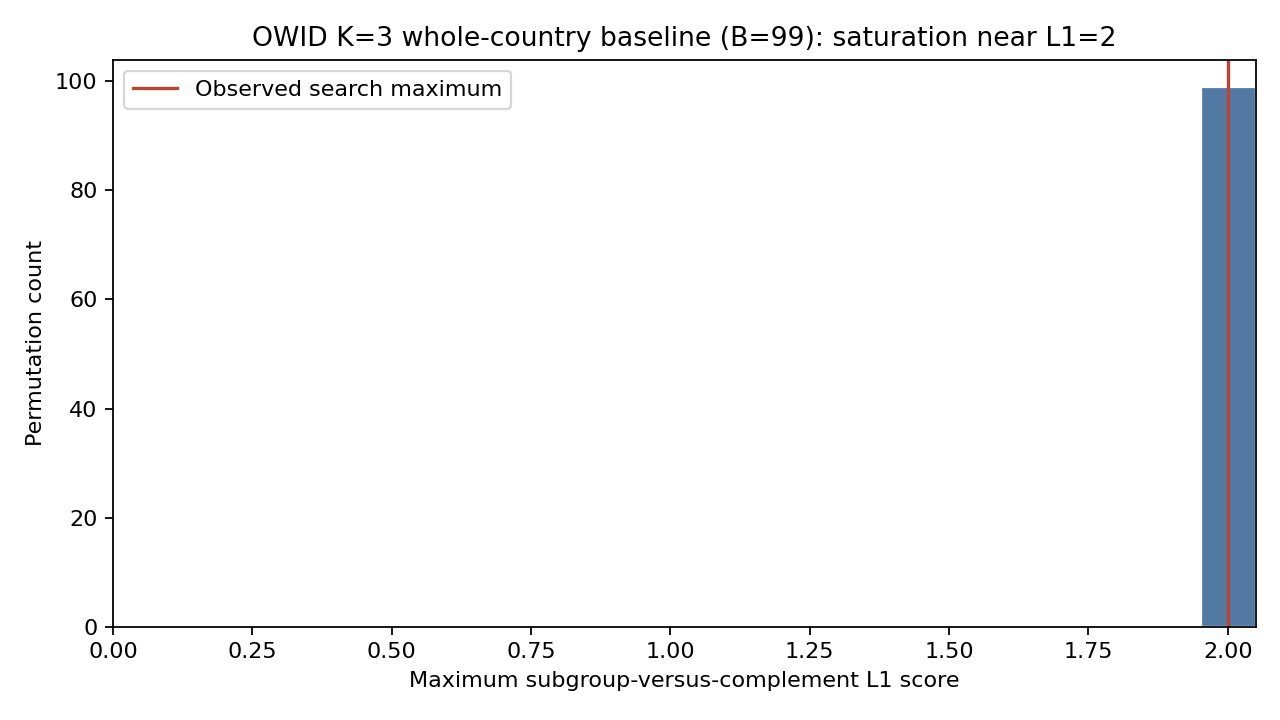

In [2]:
for k in (1, 2, 3):
    out = base / 'outputs' / f'owid_all_descriptors_k{k}_B99_2026-10-13'
    display(Markdown(f'## 5. K={k}: full experiment results'))
    display(json.loads((out / 'settings.json').read_text(encoding='utf-8')))
    display(Markdown('### Excluded regions and descriptor audit'))
    display(pd.read_csv(out / 'cohort.csv').query('not included'))
    display(pd.read_csv(out / 'descriptor_audit.csv'))
    display(Markdown('### Observed top ten rules, scores and coverage'))
    display(pd.read_csv(out / 'observed_subgroups.csv'))
    display(Markdown('### All 99 randomized search maxima'))
    with pd.option_context('display.max_rows', 110):
        display(pd.read_csv(out / 'randomized_maxima.csv'))
    display(Image(filename=str(out / 'search_maximum_baseline.png')))


## 6. Interpretation and limitations
Red line: observed search maximum. Histogram: randomized search maxima. Small tail fractions mean rarity under this particular randomization design, not fraud, causality or automatically valid statistical significance. B=99 gives resolution 0.01 and Monte Carlo uncertainty. We test the search maximum; we have not assigned independently valid p-values to all top-ten rules.

Best K=1 subgroup has 22 valid records; K=2 has 21 and only two contributing regions. K=3 has 810,000 cells and saturation near 2. These limitations are reported rather than retrospectively changing thresholds.

Engineering incident: after all 99 K=1 scores were saved, NumPy int64 prevented JSON summary serialization. We converted to Python int and recovered the summary from complete checkpoints without rerunning or replacing permutations. Recovery and timing provenance are recorded in summary.json. A validation import-path issue was also fixed before successful execution.

In [3]:
import runpy
import sys
import unittest
sys.path.insert(0, str(base / 'scripts'))
runpy.run_path(str(base / 'scripts' / 'verify_owid_99.py'))
suite = unittest.defaultTestLoader.discover(str(base / 'scripts'), pattern='test_*.py')
test_result = unittest.TextTestRunner(verbosity=1).run(suite)
assert test_result.wasSuccessful()


K=1: PASS, 99 complete searches, mappings, counts, tails and pilot reproduction


K=2: PASS, 99 complete searches, mappings, counts, tails and pilot reproduction


K=3: PASS, 99 complete searches, mappings, counts, tails and pilot reproduction
Paired K mappings verified. Twelve unit tests separately passed.


.

.

...

.

.

.

.

----------------------------------------------------------------------
Ran 12 tests in 0.612s

OK


## 7. Files and reproduction
This portable package contains notebooks/, scripts/, outputs/, vendor/ and inputs/. Open notebooks/owid_null_distribution_EN.ipynb or the Chinese counterpart. The display notebook reads saved outputs and does not automatically trigger 300 searches.

scripts/run_owid_99.py reproduces all three K experiments. scripts/explain_best_subgroups.py reproduces the observed searches to extract real memberships and diagnose the results. scripts/verify_owid_99.py checks all 99 scores, mappings, counts, matched K permutations and reproduction of the original three-shuffle pilot. Run tests with python -m unittest discover -s scripts -p 'test_*.py'. Dependencies are in requirements.txt.

Inputs include a compact ZIP containing the exact preprocessed source CSV and a country-name mapping used only for labels. CSV SHA256: 81b7b6668fc75581300143324e75583281b124b3e0411c079407cf60f0849274. Vendor code is Lucas's inspected local snapshot, not a claim about his latest remote branch; retain attribution and applicable upstream terms. Full implementation follows.

In [4]:
for name in ['run_owid_99.py', 'owid_real_pilot.py', 'country_trajectory_null.py', 'country_aware_search.py']:
    display(Markdown(f'### {name}'))
    display(Code(filename=str(base / 'scripts' / name), language='python'))


### run_owid_99.py

"""99-shuffle runs, preserving the earlier three-shuffle smoke results."""
from owid_real_pilot import run

if __name__ == '__main__':
    for k in (1, 2, 3):
        run(k=k, permutations=99, all_descriptors=True,
            output_label=f'owid_all_descriptors_k{k}_B99_2026-10-13')

### owid_real_pilot.py

"""Exploratory real-data baseline; exchangeability is NOT established."""

import hashlib
import argparse
from datetime import datetime, timezone
import json
from pathlib import Path
import random
import time
import zipfile

import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

from country_aware_search import make_country_search
from country_trajectory_null import permute_country_trajectories
from null_baseline import empirical_p_value


def run(k=1, permutations=19, all_descriptors=False, output_label=None):
    started = time.perf_counter()
    root = Path(__file__).resolve().parents[1]
    label = f'owid_all_descriptors_k{k}_2026-10-13' if all_descriptors else 'owid_real_pilot_2026-10-13'
    if output_label is not None:
        label = output_label
    output = root / 'outputs' / label
    output.mkdir(parents=True, exist_ok=True)
    archive = root / 'inputs/covid_input.zip'
    entry = 'exceptional-digit-distribution-main/data/covid_preprocessed.csv'
    with zipfile.ZipFile(archive) as source:
        digest = hashlib.sha256(source.read(entry)).hexdigest()
        with source.open(entry) as stream:
            original = pd.read_csv(stream, dtype={'code': str, 'continent': str},
                                   parse_dates=['week_start'])
    calendar = set(original.week_start)
    included = [code for code, part in original.groupby('code')
                if len(part) == len(calendar) and set(part.week_start) == calendar]
    exclusions = original.groupby('code').size().rename('rows').reset_index()
    exclusions['included'] = exclusions.code.isin(included)
    exclusions['reason'] = exclusions.included.map({True: 'identical full calendar',
                                                  False: 'incomplete calendar; not imputed'})
    exclusions.to_csv(output / 'cohort.csv', index=False)
    frame = original.loc[original.code.isin(included)].sort_values(
        ['code', 'week_start']).reset_index(drop=True)
    descriptors = ['continent', 'population_density', 'life_expectancy']
    if all_descriptors:
        descriptors = ['continent', 'population', 'population_density', 'median_age',
                       'life_expectancy', 'gdp_per_capita', 'diabetes_prevalence',
                       'people_vaccinated_per_hundred']
    assert not frame.duplicated(['code', 'week_start']).any()
    assert frame.continent.notna().all()
    descriptor_audit = pd.DataFrame([
        dict(descriptor=column, missing_rows=int(frame[column].isna().sum()),
             countries_with_multiple_values=int(frame.groupby('code')[column].nunique(dropna=False).gt(1).sum()))
        for column in descriptors])
    descriptor_audit.to_csv(output / 'descriptor_audit.csv', index=False)
    settings = dict(targets=['new_cases', 'new_deaths'], descriptors=descriptors,
                    categorical=['continent'], country_column='code', width=5,
                    depth=2 if all_descriptors else 1, n_bins=3, k=k, pad=False, minimum_counted=20,
                    minimum_effective_countries=None)
    metadata = dict(status='exploratory_not_validated_inference', csv_sha256=digest,
                    started_utc=datetime.now(timezone.utc).isoformat(),
                    rows=len(frame), countries_or_regions=frame.code.nunique(),
                    weeks=len(calendar), start=str(frame.week_start.min().date()),
                    end=str(frame.week_start.max().date()), permutations=permutations, seed=20261013,
                    settings=settings,
                    missing_policy='Targets remain NaN; joint valid digit rows only. Numeric descriptor NaNs do not satisfy numeric interval rules. No complete-case country exclusion.',
                    scope='All eight substantive descriptors, including time-varying vaccination retained at destination' if all_descriptors else 'Provisional one-condition search pilot',
                    limitation='Whole-country target trajectories inclu

### country_trajectory_null.py

"""Candidate country-trajectory randomization, not an approved COVID test."""

import pandas as pd


def permute_country_trajectories(frame, rng, *, country, time, targets,
                                 strata=()):
    targets = tuple(targets)
    strata = tuple(strata)
    keys = (country, time)
    if not targets or len(set(targets)) != len(targets):
        raise ValueError('Require unique, nonempty target columns')
    if set(targets) & set(keys + strata):
        raise ValueError('Targets must not overlap country, time or strata')
    required = list(dict.fromkeys(keys + targets + strata))
    if any(column not in frame for column in required):
        raise ValueError('Required columns are missing')
    if frame.empty or frame[list(keys + strata)].isna().any().any():
        raise ValueError('Require nonempty data and complete grouping keys')
    if frame.duplicated(list(keys)).any():
        raise ValueError('Duplicate country/time records')
    countries = list(frame[country].drop_duplicates())
    groups = {}
    calendars = {}
    for code in countries:
        block = frame.loc[frame[country] == code]
        if any(block[column].nunique(dropna=False) != 1 for column in strata):
            raise ValueError('Strata must be constant within country')
        calendars[code] = set(block[time])
        label = tuple(block[column].iloc[0] for column in strata)
        groups.setdefault(label, []).append(code)
    mapping = {}
    for members in groups.values():
        if len(members) < 2:
            raise ValueError('Each stratum needs at least two countries')
        if any(calendars[code] != calendars[members[0]] for code in members):
            raise ValueError('Countries within a stratum need identical calendars')
        sources = members.copy()
        rng.shuffle(sources)
        mapping.update(zip(members, sources))
    output = frame.copy(deep=True)
    for destination, source in mapping.items():
        mask = frame[country] == destination
        source_block = frame.loc[frame[country] == source].set_index(time)
        values = source_block.reindex(frame.loc[mask, time])[list(targets)]
        output.loc[mask, list(targets)] = values.to_numpy()
    return output, mapping

### country_aware_search.py

"""Auditable search wrapper; country coverage is optional and not approved settings."""

from dataclasses import dataclass
from functools import partial

import numpy as np
import pandas as pd

from lucas_null_adapter import EMM, digit_distribution, total_distance, make_search_best
from digit_distributions import leading_digits


@dataclass
class SearchRun:
    results: pd.DataFrame
    membership: tuple
    evaluated_candidates: int
    country_rejected_candidates: int

    @property
    def maximum(self):
        if self.results.empty:
            raise ValueError('No eligible subgroup; do not discard or silently retry')
        return float(self.results.score.max())


def make_country_search(*, targets, descriptors, categorical, country_column,
                        width=5, depth=2, n_bins=3, k=1, pad=False,
                        minimum_counted=20, minimum_effective_countries=None):
    targets, descriptors, categorical = tuple(targets), tuple(descriptors), tuple(categorical)
    make_search_best(targets=targets, descriptors=descriptors, categorical=categorical,
                     width=width, depth=depth, n_bins=n_bins, k=k, pad=pad,
                     minimum_counted=minimum_counted)
    if country_column in targets:
        raise ValueError('Country identifier cannot be a digit target')
    if minimum_effective_countries is not None:
        value = minimum_effective_countries
        if isinstance(value, bool) or not isinstance(value, int) or value < 1:
            raise ValueError('Country minimum must be None or a positive integer')
    model = partial(digit_distribution, k=k, pad=pad)

    def score(inside, outside):
        if min(inside.sum(), outside.sum()) < minimum_counted:
            return float('nan')
        value = total_distance(inside, outside)
        return value if np.isfinite(value) else float('nan')

    def run(rows):
        frame = rows.copy(deep=True) if isinstance(rows, pd.DataFrame) else pd.DataFrame(rows)
        if not frame.index.is_unique:
            raise ValueError('Unique row index required')
        if country_column not in frame or frame[country_column].isna().any():
            raise ValueError('A complete country identifier is required for the audit')
        if any(column not in frame for column in targets):
            raise ValueError('Missing target column')
        valid = pd.Series(True, index=frame.index)
        for column in targets:
            valid &= leading_digits(frame[column], k=k, pad=pad) > 0

        class AuditedEMM(EMM):
            def evaluate(self, subgroup):
                self.evaluated += 1
                super().evaluate(subgroup)
                if minimum_effective_countries is not None:
                    mask = frame.index.isin(subgroup.data.index)
                    inside = frame.loc[mask & valid, country_column].nunique()
                    outside = frame.loc[~mask & valid, country_column].nunique()
                    if min(inside, outside) < minimum_effective_countries:
                        subgroup.score = float('nan')
                        self.country_rejected += 1

        search = AuditedEMM(width, depth, model, score, n_bins=n_bins)
        search.evaluated = search.country_rejected = 0
        search.search(frame, list(categorical), list(targets), list(descriptors))
        results = search.results().copy()
        records, membership = [], []
        for subgroup in search.beam.best:
            mask = frame.index.isin(subgroup.data.index)
            count = int((mask & valid).sum())
            if count != int(subgroup.target.sum()):
                raise AssertionError('Audit eligibility disagrees with original model counts')
            records.append({'countries': frame.loc[mask, country_column].nunique(),
                            'effective_countries': frame.loc[mask & valid, country_column].nunique(),
                            'complement_counted': int((~mask & valid).sum()),
                            

## 8. Completed experiments and conclusions
All three K experiments have 99 whole-country permutations and complete repeated beam searches: 300 searches total. All corresponding mappings match across K.

| K | Observed maximum L1 | Exceedances including ties / 99 | Corrected exploratory tail |
|---|---:|---:|---:|
| 1 | 1.1981416772554 | 3 | 0.04 |
| 2 | 1.9816692667706708 | 6 | 0.07 |
| 3 | approximately 2 | 95 | 0.96 |

K=1 best rule: Oceania AND 4456.23 < gdp_per_capita <= 12134.9. K=2: Oceania AND 21.8 < diabetes_prevalence <= 25.7. K=3: North America AND 10.2 < diabetes_prevalence <= 12.7667. Original descriptor units are retained.

K=3 randomized maxima range from 1.9996823379923763 to approximately 2; runtime approximately 746.5 seconds. Across the full cohort K=3 has 6,339 valid records and about 99.23% empty joint cells. A score near 2 is not evidence of superior detection. No claim of country exchangeability, fraud detection or formally established significance is made.

### K=3 floating-point ties: important
95/99 randomized maxima equal or exceed the observed maximum with absolute tolerance 1e-12, giving (95+1)/100=0.96. Strict floating-point comparison gives only 5 exceedances and 0.06; that result is distorted by machine-precision differences near the theoretical L1 bound 2. Raw values remain in summary.json for auditing, but must not be interpreted as genuine rank evidence.

K=3 finished at 16:27 CEST on 2026-10-13. All mappings, counts, tails and pilot reproduction were verified; twelve unit tests passed. GitHub upload has not been performed.

## 9. Membership and high-score diagnosis
We rerun each original search to obtain its actual membership indices and assert agreement with the saved best rule and score. No random experiments are rerun and no eligibility thresholds changed. Actual indices avoid errors from parsing displayed quantile boundaries.

Country names come from a local OWID code-to-name mapping used only for labels. We show every contributing country-week with values and extracted prefixes. The chart shows only the twelve digit pairs with the largest L1 contributions; complete occupied pairs are saved in all_occupied_digit_pairs.csv. The year chart counts valid country-week records, not cases or deaths.

Invalid-reason categories are mutually exclusive with priority: missing, infinite, negative, zero, below the K-digit threshold, then valid. They are not independent per-target counts. These are preprocessed weekly values: zero may reflect reporting practices and cannot always be interpreted as no actual disease.

,k,rule,l1,total_rows,valid_rows,valid_fraction,countries,effective_countries,largest_country_valid_share,shared_probability_mass,subgroup_occupied_pairs,complement_occupied_pairs,shared_occupied_pairs,top12_l1_contribution,source_csv_sha256,audited_utc,interpretation
0,1,continent = oceania AND 4456.23 < gdp_per_capi...,1.198142,1305,22,0.016858,5,5,0.500000,0.400929,15,81,15,0.564142,81b7b6668fc75581300143324e75583281b124b3e0411c...,2026-10-13T14:49:17.854493+00:00,"Post-search descriptive diagnosis, not additio..."
1,2,continent = oceania AND 21.8 < diabetes_preval...,1.981669,1305,21,0.016092,5,2,0.666667,0.009165,21,5189,20,0.569934,81b7b6668fc75581300143324e75583281b124b3e0411c...,2026-10-13T14:49:20.926353+00:00,"Post-search descriptive diagnosis, not additio..."
2,3,continent = north america AND 10.2 < diabetes_...,2.000000,2610,48,0.018391,10,5,0.520833,0.000000,48,6222,0,0.250000,81b7b6668fc75581300143324e75583281b124b3e0411c...,2026-10-13T14:49:31.506180+00:00,"Post-search descriptive diagnosis, not additio..."


### K=1: members, eligible weeks and distribution differences

{'k': 1,
 'rule': 'continent = oceania AND 4456.23 < gdp_per_capita <= 12134.9',
 'l1': 1.1981416772554003,
 'total_rows': 1305,
 'valid_rows': 22,
 'valid_fraction': 0.01685823754789272,
 'countries': 5,
 'effective_countries': 5,
 'largest_country_valid_share': 0.5,
 'shared_probability_mass': 0.40092916137229984,
 'subgroup_occupied_pairs': 15,
 'complement_occupied_pairs': 81,
 'shared_occupied_pairs': 15,
 'top12_l1_contribution': 0.5641424569712372,
 'source_csv_sha256': '81b7b6668fc75581300143324e75583281b124b3e0411c079407cf60f0849274',
 'audited_utc': '2026-10-13T14:49:17.854493+00:00',
 'interpretation': 'Post-search descriptive diagnosis, not additional independent significance or fraud evidence.'}

#### All selected regions, including regions with zero eligible records

,code,country_name,total_weeks,valid_weeks,first_valid_week,last_valid_week,valid_fraction
0,mhl,Marshall Islands,261,4,2022-08-08,2022-08-29,0.015326
1,nru,Nauru,261,1,2022-06-27,2022-06-27,0.003831
2,ton,Tonga,261,5,2022-03-07,2024-08-05,0.019157
3,tuv,Tuvalu,261,1,2023-06-12,2023-06-12,0.003831
4,wsm,Samoa,261,11,2022-03-28,2022-06-20,0.042146


...

,year,total_weeks,valid_weeks
0,2020,260,0
1,2021,260,0
2,2022,260,20
3,2023,260,1
4,2024,265,1


#### Every contributing country-week record

,country_name,code,week_start,new_cases,new_deaths,cases_prefix,deaths_prefix
0,Marshall Islands,mhl,2022-08-08,758.0,5.0,7,5
1,Marshall Islands,mhl,2022-08-15,9086.0,9.0,9,9
2,Marshall Islands,mhl,2022-08-22,4885.0,2.0,4,2
3,Marshall Islands,mhl,2022-08-29,266.0,1.0,2,1
4,Nauru,nru,2022-06-27,1565.0,1.0,1,1
5,Tonga,ton,2022-03-07,861.0,2.0,8,2
6,Tonga,ton,2022-03-28,1536.0,7.0,1,7
7,Tonga,ton,2022-04-11,1094.0,2.0,1,2
8,Tonga,ton,2022-05-23,156.0,1.0,1,1
9,Tonga,ton,2024-08-05,13.0,1.0,1,1


#### Twelve digit pairs contributing most to L1

,cases_prefix,deaths_prefix,subgroup_count,complement_count,subgroup_share,complement_share,absolute_difference
0,1,1,4.0,2490,0.181818,0.098872,0.082946
1,4,2,2.0,454,0.090909,0.018027,0.072882
2,7,1,2.0,509,0.090909,0.020211,0.070698
3,9,9,1.0,37,0.045455,0.001469,0.043985
4,3,1,0.0,1062,0.000000,0.042170,0.042170
5,7,5,1.0,105,0.045455,0.004169,0.041285
6,1,3,0.0,990,0.000000,0.039311,0.039311
7,2,6,1.0,260,0.045455,0.010324,0.035131
8,8,2,1.0,267,0.045455,0.010602,0.034853
9,2,1,2.0,1421,0.090909,0.056425,0.034484


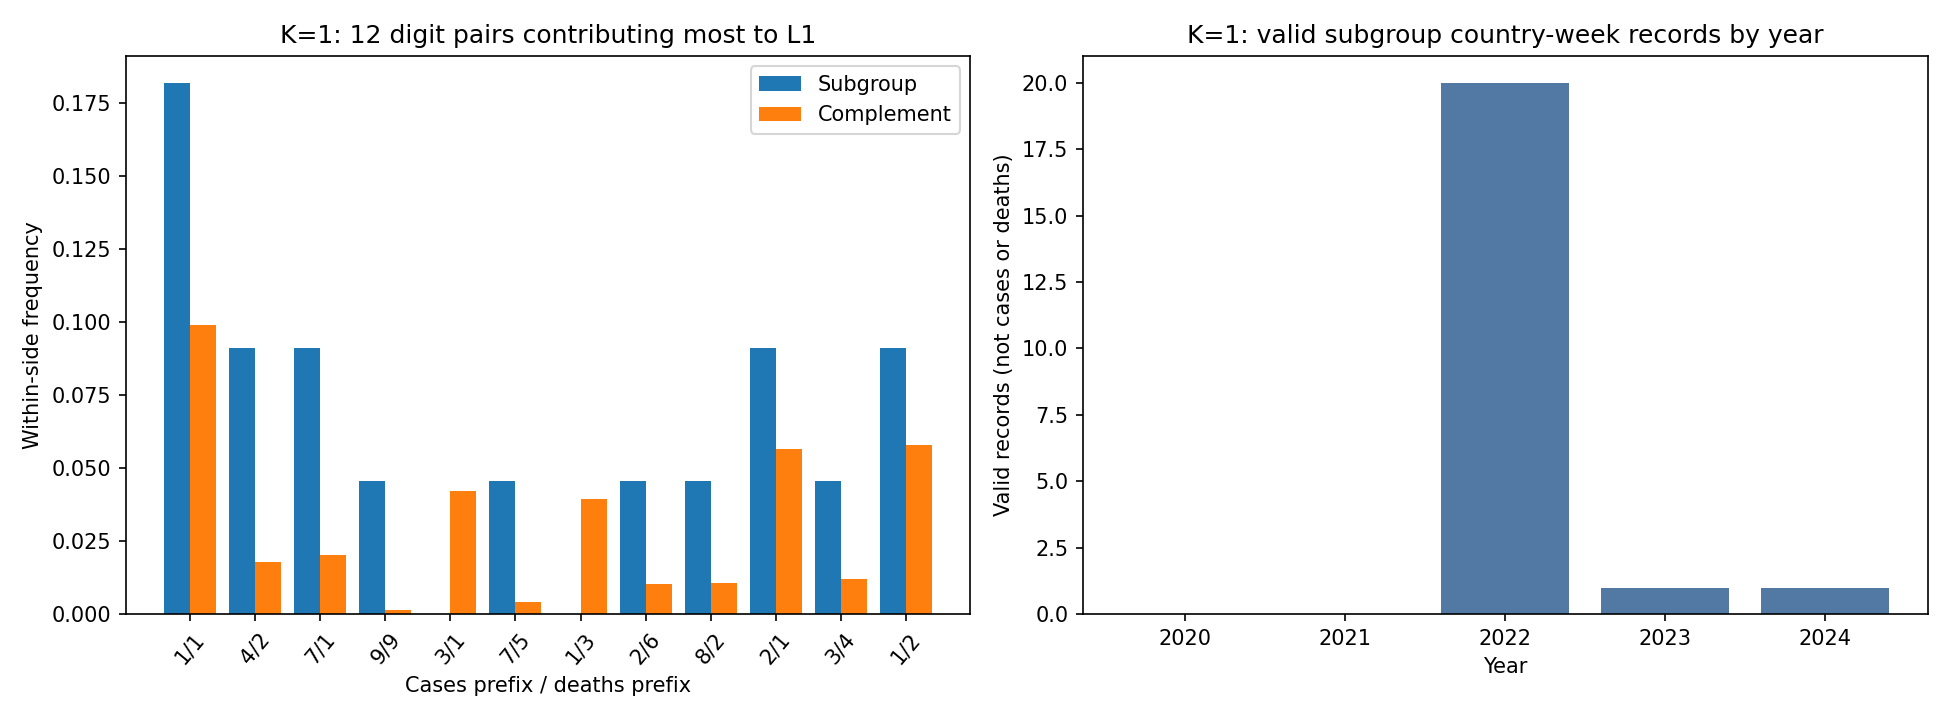

### K=2: members, eligible weeks and distribution differences

{'k': 2,
 'rule': 'continent = oceania AND 21.8 < diabetes_prevalence <= 25.7',
 'l1': 1.9816692667706708,
 'total_rows': 1305,
 'valid_rows': 21,
 'valid_fraction': 0.016091954022988506,
 'countries': 5,
 'effective_countries': 2,
 'largest_country_valid_share': 0.6666666666666666,
 'shared_probability_mass': 0.009165366614664588,
 'subgroup_occupied_pairs': 21,
 'complement_occupied_pairs': 5189,
 'shared_occupied_pairs': 20,
 'top12_l1_contribution': 0.5699335116261792,
 'source_csv_sha256': '81b7b6668fc75581300143324e75583281b124b3e0411c079407cf60f0849274',
 'audited_utc': '2026-10-13T14:49:20.926353+00:00',
 'interpretation': 'Post-search descriptive diagnosis, not additional independent significance or fraud evidence.'}

#### All selected regions, including regions with zero eligible records

,code,country_name,total_weeks,valid_weeks,first_valid_week,last_valid_week,valid_fraction
0,kir,Kiribati,261,0,NaN,NaN,0.00000
1,mhl,Marshall Islands,261,0,NaN,NaN,0.00000
2,ncl,New Caledonia,261,7,2021-09-13,2022-02-21,0.02682
3,pyf,French Polynesia,261,14,2020-11-02,2021-09-27,0.05364
4,wsm,Samoa,261,0,NaN,NaN,0.00000


#### Eligibility exclusions and annual coverage

...

,year,total_weeks,valid_weeks
0,2020,260,6
1,2021,260,14
2,2022,260,1
3,2023,260,0
4,2024,265,0


#### Every contributing country-week record

,country_name,code,week_start,new_cases,new_deaths,cases_prefix,deaths_prefix
0,New Caledonia,ncl,2021-09-13,2574.0,21.0,25,21
1,New Caledonia,ncl,2021-09-20,2654.0,61.0,26,61
2,New Caledonia,ncl,2021-09-27,1804.0,67.0,18,67
3,New Caledonia,ncl,2021-10-04,1177.0,50.0,11,50
4,New Caledonia,ncl,2021-10-11,811.0,41.0,81,41
5,New Caledonia,ncl,2021-10-18,505.0,16.0,50,16
6,New Caledonia,ncl,2022-02-21,9122.0,12.0,91,12
7,French Polynesia,pyf,2020-11-02,2733.0,10.0,27,10
8,French Polynesia,pyf,2020-11-09,1711.0,14.0,17,14
9,French Polynesia,pyf,2020-11-16,1272.0,10.0,12,10


#### Twelve digit pairs contributing most to L1

,cases_prefix,deaths_prefix,subgroup_count,complement_count,subgroup_share,complement_share,absolute_difference
0,58,31,1.0,0.0,0.047619,0.000000,0.047619
1,80,69,1.0,1.0,0.047619,0.000065,0.047554
2,81,41,1.0,1.0,0.047619,0.000065,0.047554
3,11,50,1.0,1.0,0.047619,0.000065,0.047554
4,18,67,1.0,1.0,0.047619,0.000065,0.047554
5,16,71,1.0,2.0,0.047619,0.000130,0.047489
6,26,61,1.0,2.0,0.047619,0.000130,0.047489
7,90,42,1.0,2.0,0.047619,0.000130,0.047489
8,91,12,1.0,3.0,0.047619,0.000195,0.047424
9,19,95,1.0,3.0,0.047619,0.000195,0.047424


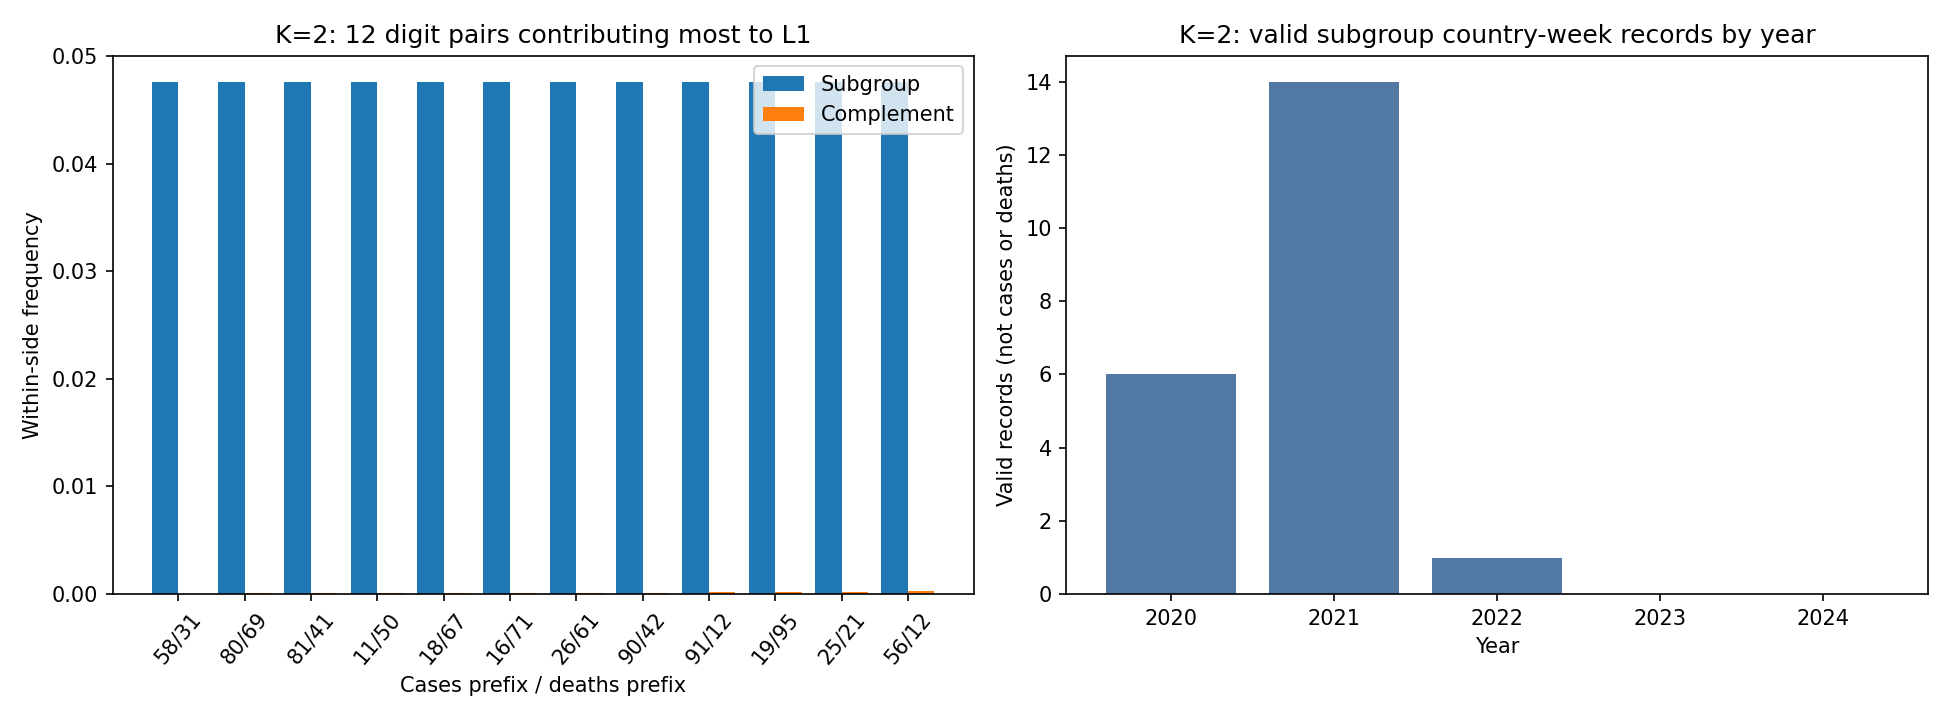

### K=3: members, eligible weeks and distribution differences

{'k': 3,
 'rule': 'continent = north america AND 10.2 < diabetes_prevalence <= 12.7667',
 'l1': 1.9999999999999996,
 'total_rows': 2610,
 'valid_rows': 48,
 'valid_fraction': 0.01839080459770115,
 'countries': 10,
 'effective_countries': 5,
 'largest_country_valid_share': 0.5208333333333334,
 'shared_probability_mass': 0.0,
 'subgroup_occupied_pairs': 48,
 'complement_occupied_pairs': 6222,
 'shared_occupied_pairs': 0,
 'top12_l1_contribution': 0.25,
 'source_csv_sha256': '81b7b6668fc75581300143324e75583281b124b3e0411c079407cf60f0849274',
 'audited_utc': '2026-10-13T14:49:31.506180+00:00',
 'interpretation': 'Post-search descriptive diagnosis, not additional independent significance or fraud evidence.'}

#### All selected regions, including regions with zero eligible records

,code,country_name,total_weeks,valid_weeks,first_valid_week,last_valid_week,valid_fraction
0,atg,Antigua and Barbuda,261,0,NaN,NaN,0.000000
1,cym,Cayman Islands,261,0,NaN,NaN,0.000000
2,grd,Grenada,261,0,NaN,NaN,0.000000
3,jam,Jamaica,261,5,2021-08-23,2021-10-11,0.019157
4,lca,Saint Lucia,261,0,NaN,NaN,0.000000
5,nic,Nicaragua,261,0,NaN,NaN,0.000000
6,pan,Panama,261,25,2020-06-29,2022-02-07,0.095785
7,pri,Puerto Rico,261,7,2020-11-23,2022-01-24,0.026820
8,slv,El Salvador,261,1,2021-10-04,2021-10-04,0.003831
9,tto,Trinidad and Tobago,261,10,2021-05-24,2022-01-17,0.038314


#### Eligibility exclusions and annual coverage

...

,year,total_weeks,valid_weeks
0,2020,520,18
1,2021,520,21
2,2022,520,9
3,2023,520,0
4,2024,530,0


#### Every contributing country-week record

,country_name,code,week_start,new_cases,new_deaths,cases_prefix,deaths_prefix
0,Jamaica,jam,2021-08-23,4452.0,112.0,445,112
1,Jamaica,jam,2021-08-30,4923.0,110.0,492,110
2,Jamaica,jam,2021-09-06,4640.0,111.0,464,111
3,Jamaica,jam,2021-10-04,1488.0,111.0,148,111
4,Jamaica,jam,2021-10-11,1327.0,108.0,132,108
5,Panama,pan,2020-06-29,6090.0,123.0,609,123
6,Panama,pan,2020-07-06,7262.0,165.0,726,165
7,Panama,pan,2020-07-13,8151.0,175.0,815,175
8,Panama,pan,2020-07-20,6585.0,212.0,658,212
9,Panama,pan,2020-07-27,7263.0,171.0,726,171


#### Twelve digit pairs contributing most to L1

,cases_prefix,deaths_prefix,subgroup_count,complement_count,subgroup_share,complement_share,absolute_difference
0,358,133,1.0,0.0,0.020833,0.0,0.020833
1,295,151,1.0,0.0,0.020833,0.0,0.020833
2,118,124,1.0,0.0,0.020833,0.0,0.020833
3,465,178,1.0,0.0,0.020833,0.0,0.020833
4,445,112,1.0,0.0,0.020833,0.0,0.020833
5,492,110,1.0,0.0,0.020833,0.0,0.020833
6,464,111,1.0,0.0,0.020833,0.0,0.020833
7,148,111,1.0,0.0,0.020833,0.0,0.020833
8,132,108,1.0,0.0,0.020833,0.0,0.020833
9,609,123,1.0,0.0,0.020833,0.0,0.020833


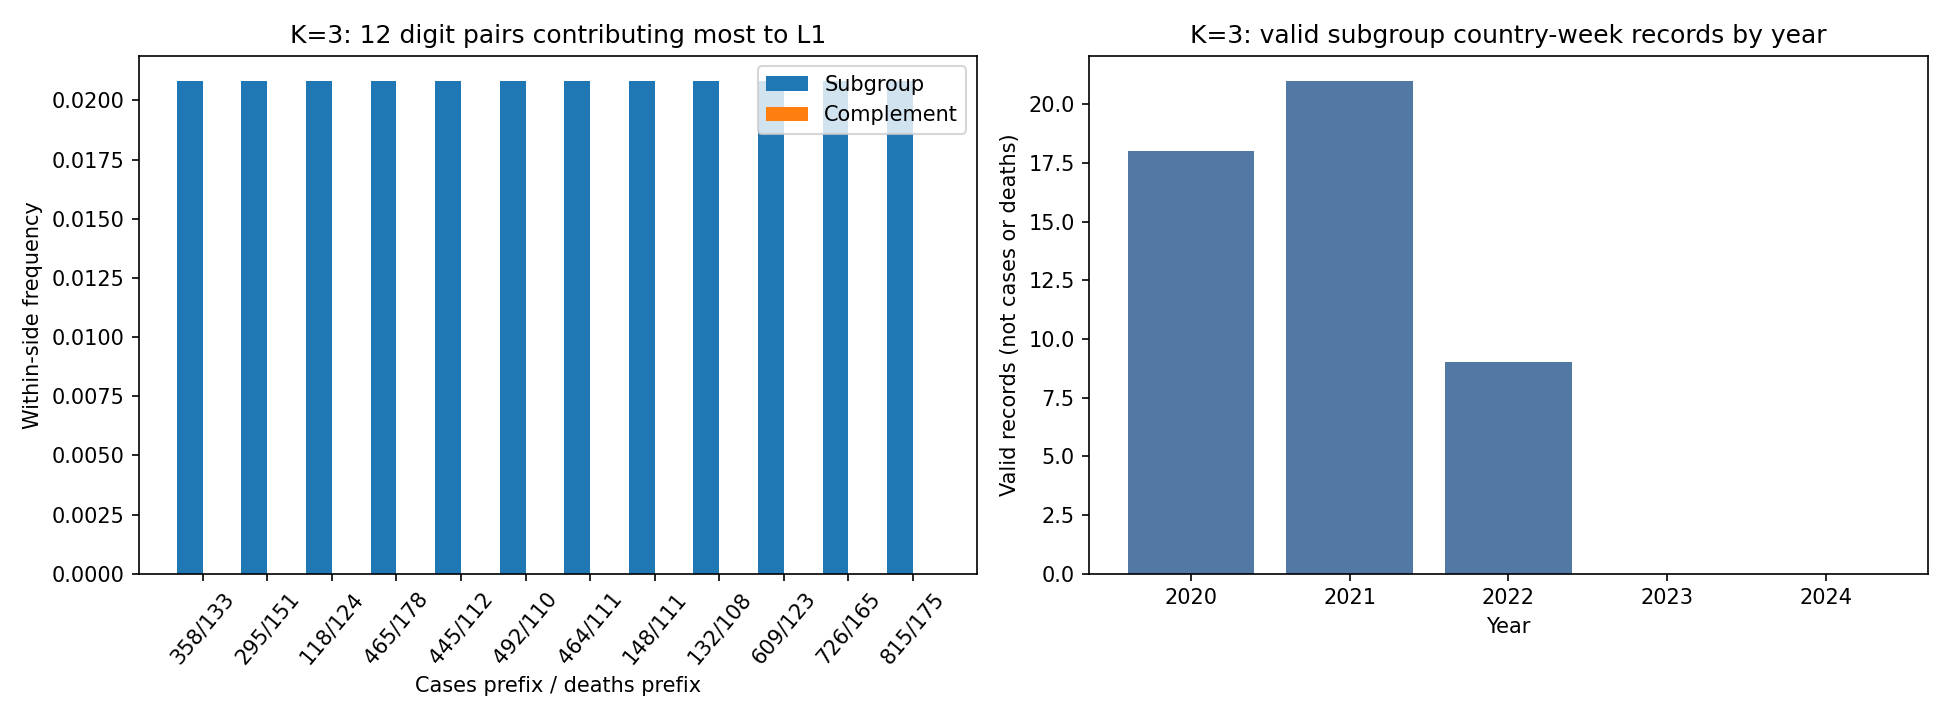

In [5]:
details_root = base / 'outputs' / 'best_subgroup_explanations_2026-10-13'
display(pd.read_csv(details_root / 'summary.csv'))
for k in (1, 2, 3):
    folder = details_root / f'k{k}'
    display(Markdown(f'### K={k}: members, eligible weeks and distribution differences'))
    display(json.loads((folder / 'summary.json').read_text(encoding='utf-8')))
    display(Markdown('#### All selected regions, including regions with zero eligible records'))
    display(pd.read_csv(folder / 'countries.csv'))
    display(Markdown('#### Eligibility exclusions and annual coverage'))
    display(pd.read_csv(folder / 'eligibility_reasons.csv'))
    display(pd.read_csv(folder / 'annual_validity.csv'))
    display(Markdown('#### Every contributing country-week record'))
    columns = ['country_name', 'code', 'week_start', 'new_cases', 'new_deaths', 'cases_prefix', 'deaths_prefix']
    with pd.option_context('display.max_rows', 100):
        display(pd.read_csv(folder / 'valid_subgroup_weeks.csv')[columns])
    display(Markdown('#### Twelve digit pairs contributing most to L1'))
    display(pd.read_csv(folder / 'all_occupied_digit_pairs.csv').head(12))
    display(Image(filename=str(folder / 'digit_difference_and_valid_weeks.png')))


### Diagnosis conclusions
**K=1:** five regions have 1,305 rows but only 22 jointly valid records (1.69%). 1,282 rows contain at least one zero and one contains at least one missing target. Samoa contributes 11 valid records; Tonga five, Marshall Islands four, Nauru one, Tuvalu one. The result describes these 22 records, not a stable five-year regional epidemic feature.

**K=2:** five selected regions, but only New Caledonia (seven records) and French Polynesia (fourteen) contribute. Kiribati, Marshall Islands and Samoa have zero eligible records. Twenty records are in 2020–2021, one in 2022, none in 2023–2024. All 21 records occupy different digit pairs. Twenty pairs also occur in the complement, yet overlap probability mass is only about 0.00917, explaining L1 approximately 1.9817. Shared cells do not imply similar frequencies.

**K=3:** 48 valid records occupy 48 unique pairs and share no pair with the complement. Overlap mass=0, so L1=2 within floating-point precision. This directly explains saturation; the 0.96 randomized tail also shows no rarity.

These are descriptive post-search diagnoses, not new independent tests. They do not prove zeros/missingness are the sole cause or establish fraud or causality. No country threshold was added. Full selected rows, all valid rows, country coverage, invalid reasons, annual counts and digit pairs are saved in outputs/best_subgroup_explanations_2026-10-13/k1, k2 and k3.

In [6]:
display(Code(filename=str(base / 'scripts' / 'explain_best_subgroups.py'), language='python'))

"""Reproduce original searches and audit actual memberships; no permutation reruns."""
from datetime import datetime, timezone
import json
from pathlib import Path
import zipfile
import hashlib
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from country_aware_search import make_country_search
from digit_distributions import leading_digits


def run():
    root = Path(__file__).resolve().parents[1]
    out = root / 'outputs/best_subgroup_explanations_2026-10-13'
    out.mkdir(parents=True, exist_ok=True)
    with zipfile.ZipFile(Path(__file__).resolve().parents[1] / 'inputs/covid_input.zip') as archive:
        entry = 'exceptional-digit-distribution-main/data/covid_preprocessed.csv'
        digest = hashlib.sha256(archive.read(entry)).hexdigest()
        with archive.open(entry) as stream:
            original = pd.read_csv(stream, parse_dates=['week_start'], dtype={'code': str})
    cohort = pd.read_csv(root / 'outputs/owid_all_descriptors_k1_B99_2026-10-13/cohort.csv')
    frame = original[original.code.isin(cohort.loc[cohort.included, 'code'])].sort_values(
        ['code', 'week_start']).reset_index(drop=True)
    name_file = root / 'inputs/country_names.csv'
    names = pd.read_csv(name_file, usecols=['code', 'country']).drop_duplicates()
    names['code'] = names.code.str.lower()
    assert names.groupby('code').country.nunique().le(1).all()
    names = names.set_index('code').country.to_dict()
    summaries = []
    for k in (1, 2, 3):
        folder = out / f'k{k}'
        folder.mkdir(exist_ok=True)
        source = root / f'outputs/owid_all_descriptors_k{k}_B99_2026-10-13'
        metadata = json.loads((source / 'settings.json').read_text(encoding='utf-8'))
        assert digest == metadata['csv_sha256']
        search = make_country_search(**metadata['settings'])(frame)
        saved = pd.read_csv(source / 'observed_subgroups.csv')
        assert search.results.description.iloc[0] == saved.description.iloc[0]
        assert np.isclose(search.maximum, saved.score.iloc[0], atol=1e-12, rtol=0)
        mask = frame.index.isin(search.membership[0])
        values = frame[['new_cases', 'new_deaths']].to_numpy(dtype=float)
        digits = np.column_stack([leading_digits(frame[column], k=k, pad=False)
                                  for column in ['new_cases', 'new_deaths']])
        valid = (digits > 0).all(axis=1)
        reason = np.full(len(frame), 'valid', dtype=object)
        reason[~valid] = 'below_digit_threshold'
        reason[(values == 0).any(axis=1)] = 'at_least_one_zero'
        reason[(values < 0).any(axis=1)] = 'at_least_one_negative'
        reason[np.isinf(values).any(axis=1)] = 'at_least_one_infinite'
        reason[np.isnan(values).any(axis=1)] = 'at_least_one_missing'
        assert np.array_equal(reason == 'valid', valid)
        annotated = frame.copy()
        annotated['country_name'] = annotated.code.map(names).fillna(annotated.code)
        annotated['eligible'] = valid
        annotated['eligibility_reason'] = reason
        annotated['cases_prefix'] = digits[:, 0]
        annotated['deaths_prefix'] = digits[:, 1]
        group = annotated.loc[mask]
        group.to_csv(folder / 'all_subgroup_weeks.csv', index=False)
        group.loc[group.eligible].to_csv(folder / 'valid_subgroup_weeks.csv', index=False)
        countries = group.groupby(['code', 'country_name'], sort=True).agg(
            total_weeks=('eligible', 'size'), valid_weeks=('eligible', 'sum'),
            first_valid_week=('week_start', lambda s: group.loc[s.index][group.loc[s.index, 'eligible']].week_start.min()),
            last_valid_week=('week_start', lambda s: group.loc[s.index][group.loc[s.index, 'eligible']].week_start.max()))
        countries['valid_fraction'] = countries.valid_weeks / countries.total_weeks
        countries.to_csv(folder / 'countries.csv')
        states = annotated.assign(side=np.where(mask, 'subgroup', 'complement')).groupby(
        